## *Materials Dataset ML Project*

The Material Dataset includes the following mechanical properties:

- Standard (Std)
- Unique Identification code for the Material (ID)
- Material Name
- Heat Treatment Method
- Ultimate Tensile Strength (Su) in MPa
- Yield Strength (Sy) in MPa
- Elongation at Break or Strain (A5) as a Percentage
- Brinell Hardness Number (BHN) in Microhardness Units
- Elastic Modulus (E) in MPa
- Shear Modulus (G) in MPa
- Poisson's Ratio (mu) in Units of Length
- Density (Ro) in Kg/m3
- Pressure at Yield (pH) in MPa
- Description of the Material (Desc)
- Vickers Hardness Number (HV)

### Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Read dataset

In [4]:
df = pd.read_csv("Data.csv")
df.head()

,Std,ID,Material,Heat treatment,Su,Sy,A5,Bhn,E,G,mu,Ro,pH,Desc,HV
0,ANSI,D8894772B88F495093C43AF905AB6373,Steel SAE 1015,as-rolled,421,314,39.0,126.0,207000,79000,0.3,7860,NaN,NaN,NaN
1,ANSI,05982AC66F064F9EBC709E7A4164613A,Steel SAE 1015,normalized,424,324,37.0,121.0,207000,79000,0.3,7860,NaN,NaN,NaN
2,ANSI,356D6E63FF9A49A3AB23BF66BAC85DC3,Steel SAE 1015,annealed,386,284,37.0,111.0,207000,79000,0.3,7860,NaN,NaN,NaN
3,ANSI,1C758F8714AC4E0D9BD8D8AE1625AECD,Steel SAE 1020,as-rolled,448,331,36.0,143.0,207000,79000,0.3,7860,NaN,NaN,NaN
4,ANSI,DCE10036FC1946FC8C9108D598D116AD,Steel SAE 1020,normalized,441,346,35.8,131.0,207000,79000,0.3,7860,550.0,NaN,NaN


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1552 entries, 0 to 1551
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Std             1552 non-null   object 
 1   ID              1552 non-null   object 
 2   Material        1552 non-null   object 
 3   Heat treatment  802 non-null    object 
 4   Su              1552 non-null   int64  
 5   Sy              1552 non-null   object 
 6   A5              1346 non-null   float64
 7   Bhn             463 non-null    float64
 8   E               1552 non-null   int64  
 9   G               1552 non-null   int64  
 10  mu              1552 non-null   float64
 11  Ro              1552 non-null   int64  
 12  pH              193 non-null    float64
 13  Desc            981 non-null    object 
 14  HV              165 non-null    float64
dtypes: float64(5), int64(4), object(6)
memory usage: 182.0+ KB


In [6]:
df.describe()

,Su,A5,Bhn,E,G,mu,Ro,pH,HV
count,1552.000000,1346.000000,463.000000,1552.000000,1552.000000,1552.000000,1552.000000,193.000000,165.000000
mean,572.753222,19.329421,177.138229,164571.520619,85598.840206,0.302977,6929.843428,627.393782,328.484848
std,326.834927,12.422004,113.508044,56135.405867,125326.800138,0.024590,2115.171710,370.530293,202.764089
min,69.000000,0.500000,19.000000,73000.000000,26000.000000,0.200000,1750.000000,190.000000,105.000000
25%,340.000000,11.000000,78.000000,105000.000000,40000.000000,0.300000,7160.000000,370.000000,192.000000
50%,500.000000,16.000000,170.000000,206000.000000,79000.000000,0.300000,7860.000000,460.000000,230.000000
75%,705.000000,24.375000,229.000000,206000.000000,80000.000000,0.320000,7860.000000,796.000000,492.000000
max,2220.000000,70.000000,627.000000,219000.000000,769000.000000,0.350000,8930.000000,1360.000000,800.000000


### Data cleaning

- The dataset contains 15 variables. 6 are object type, 5 are integers and 5 are float type
- The Yield strength (Sy) variable is stored as a object type. This variable should be converted to interger

In [7]:
df_clean = df.copy()
# Extract only numbers
df_clean["Sy"] = df_clean["Sy"].str.extract(r'(\d+)') 
# Convert to integer
df_clean["Sy"] = df_clean["Sy"].astype("int")

### Exploratory Data Analysis

In [8]:
df_clean.columns

Index(['Std', 'ID', 'Material', 'Heat treatment', 'Su', 'Sy', 'A5', 'Bhn', 'E',
       'G', 'mu', 'Ro', 'pH', 'Desc', 'HV'],
      dtype='object')

In [9]:
numvars = df_clean[[#'Std', 'ID', 'Material', 'Heat treatment',
                   'Su', 'Sy', 'A5', 'Bhn', 'E',
                   'G', 'mu', 'Ro', 'pH',
                   #'Desc',
                   'HV']].copy()

#### First plot of numerical values

In [10]:
#use plot style
plt.style.use('ggplot')
sns.set_theme(context="notebook", style="darkgrid")

#### Physical Properties

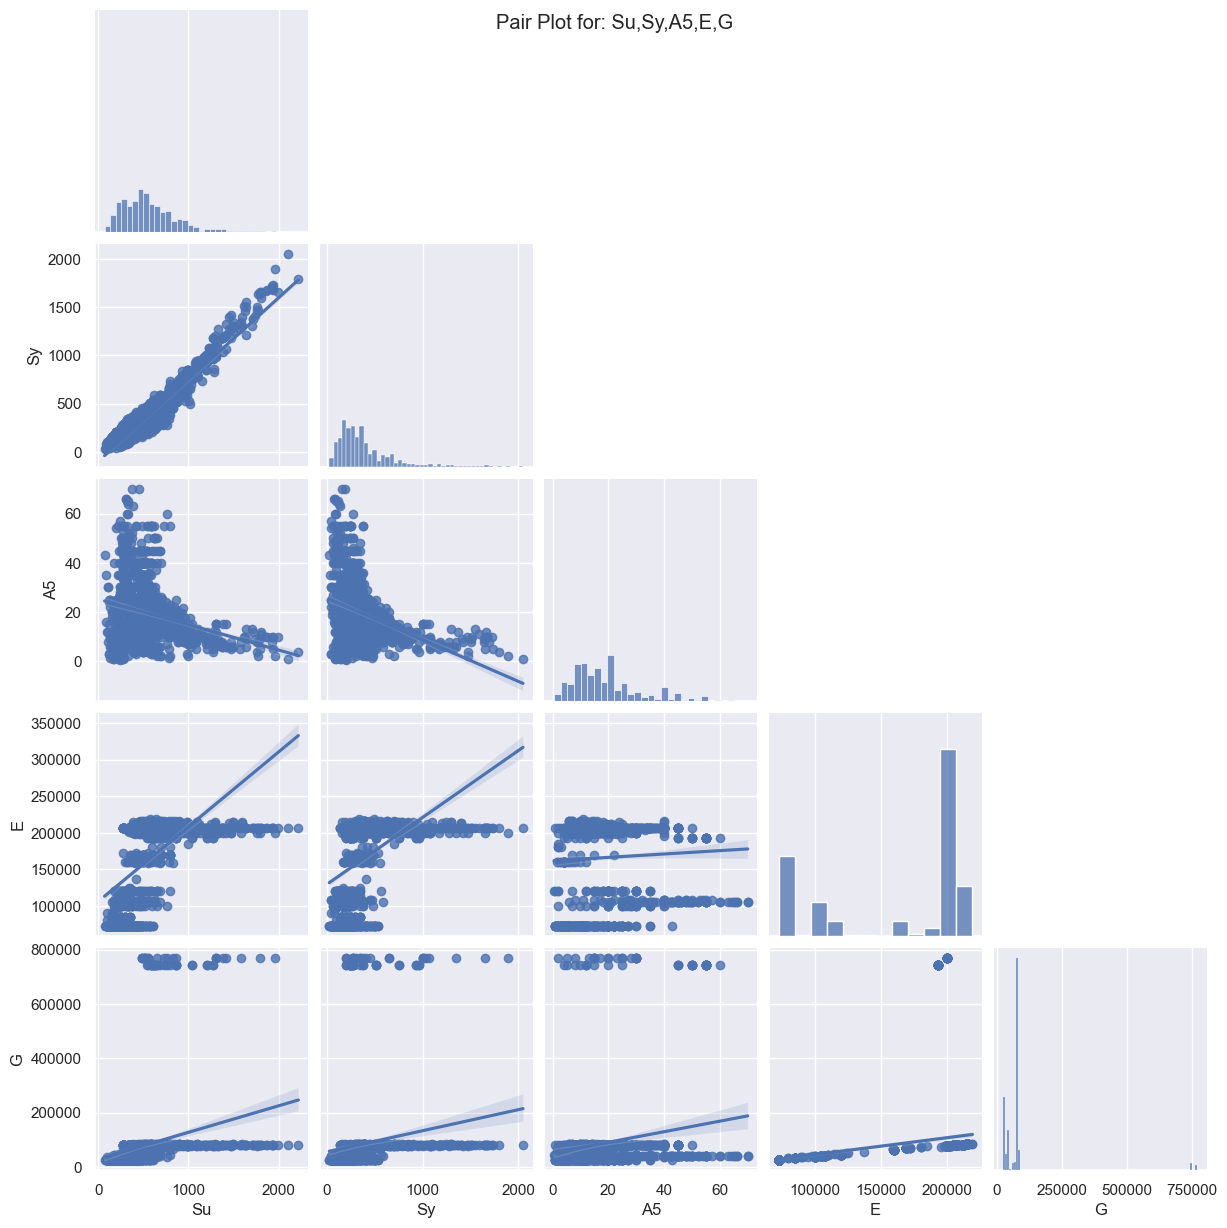

In [11]:
phys_props_main = ['Su', 'Sy', 'A5', 'E', 'G']
phys_prop_comp = ['Bhn','mu', 'Ro', 'pH', 'HV']

def pairplot_prop(vars_input):
    sns.pairplot(data = numvars,
        vars = vars_input,
        kind = "reg",
        dropna=True,
        corner=True)
    # Add a title for subset of variables
    plt.suptitle(f'Pair Plot for: {",".join(vars_input)}') 
    plt.show()

pairplot_prop(phys_props_main)

- There is a lot of data missing, the numerical values were plotted in two groups. The main properties (Yield strength, Ultimate strengt, Strain, Elastic and Shear modulus). The second group (Brinnel Hardness, Poisson's ratio, Density, Pressure at yield and Vickers Hardness)

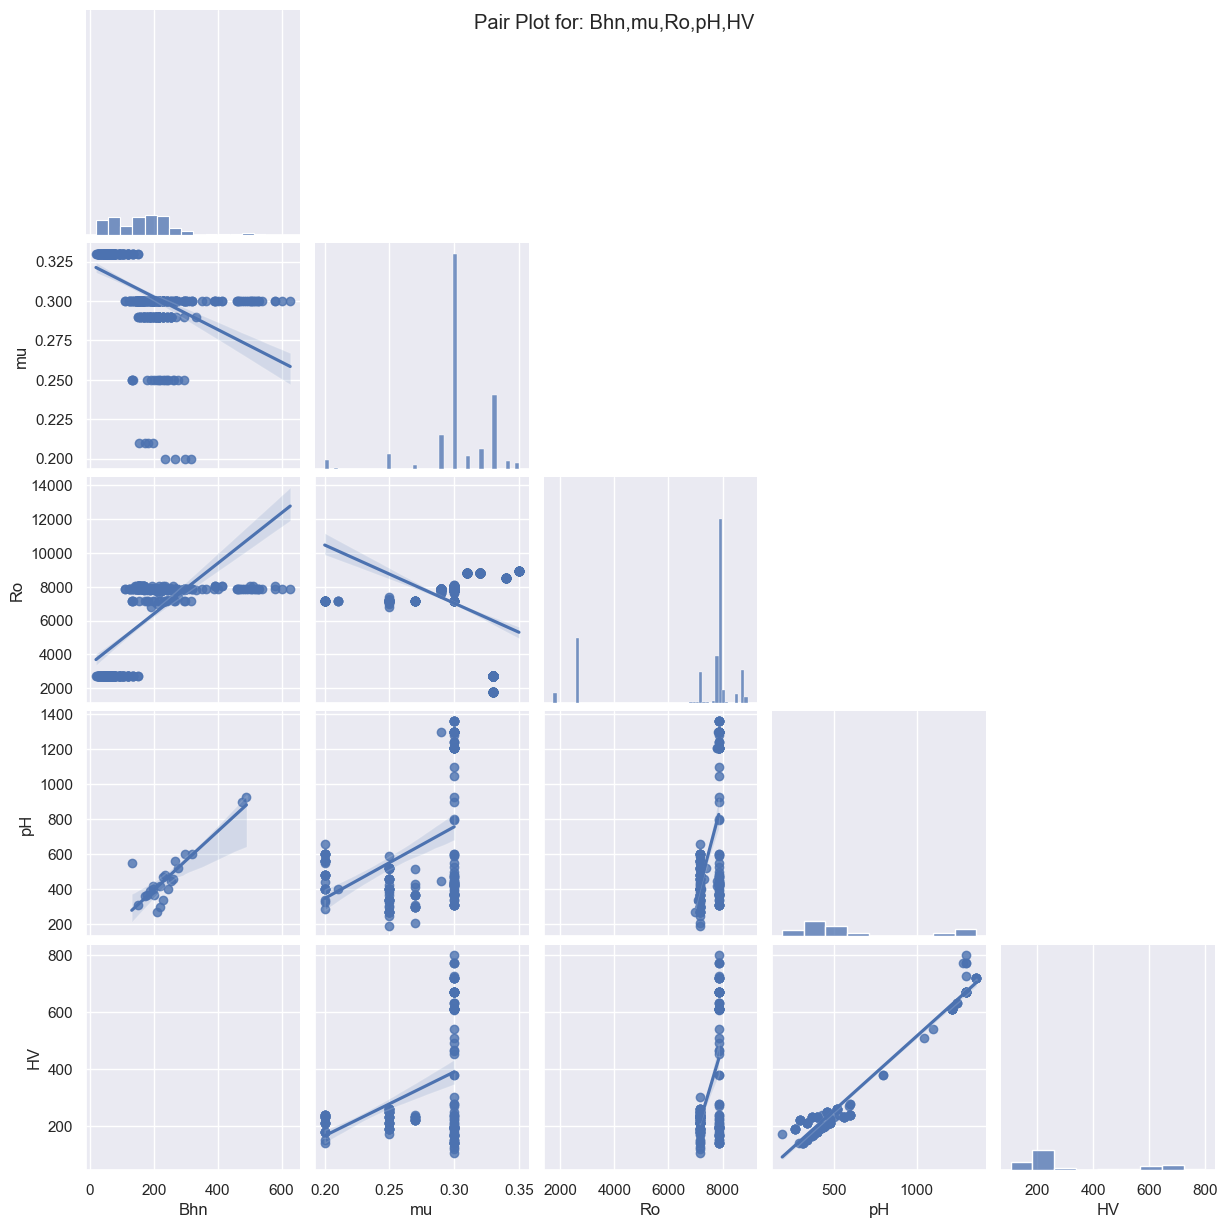

In [12]:
pairplot_prop(phys_prop_comp)

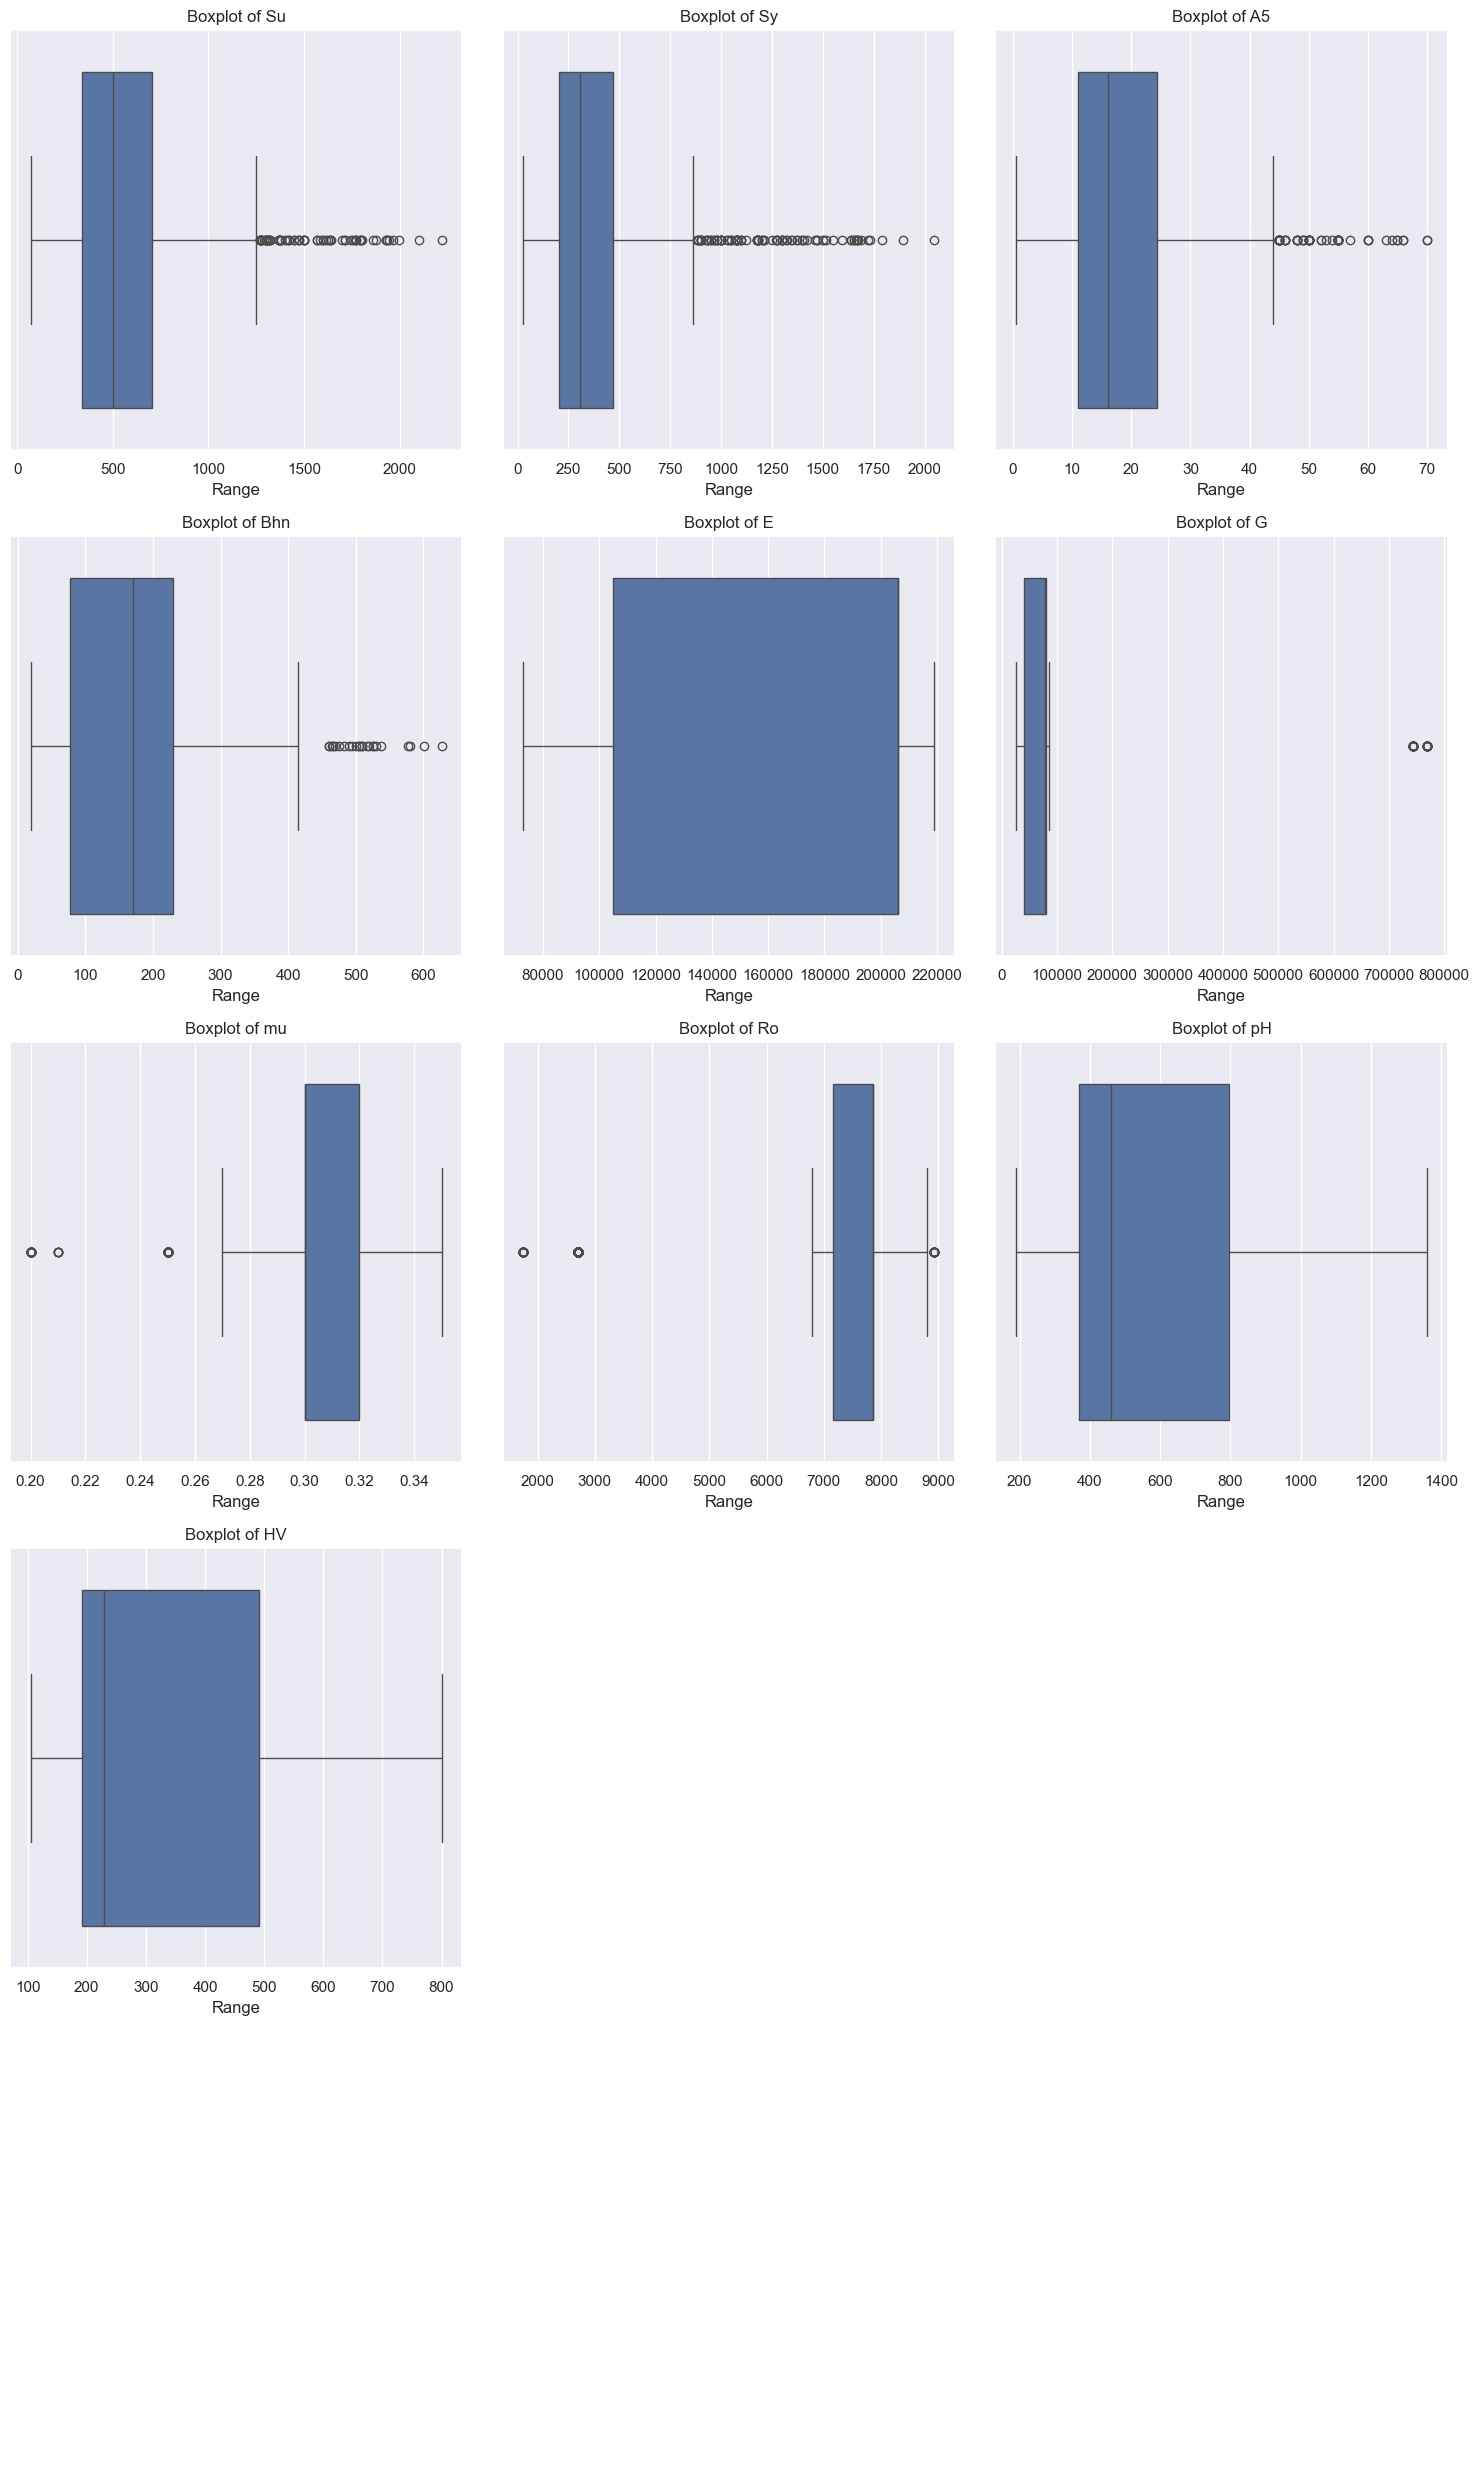

In [13]:
def plot_boxplots(data):
    num_cols = df.shape[1]
    cols_per_row = 3
    rows = -(-num_cols // cols_per_row)  # Ceiling division

    # Create subplots
    fig, axes = plt.subplots(rows, cols_per_row, figsize=(5*cols_per_row,5*rows))

    # Convert axes to a flat list of Axes objects
    if rows == 1:
        axes = axes if isinstance(axes, (list, np.ndarray)) else [axes]
    else:
        axes = axes.flatten()

    # Plot each boxplot
    for i, col in enumerate(data.columns):
        sns.boxplot(x=data[col], ax=axes[i])
        axes[i].set_title(f'Boxplot of {col}')
        axes[i].set_xlabel('Range')

    # Hide unused subplots
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()
    
plot_boxplots(numvars)

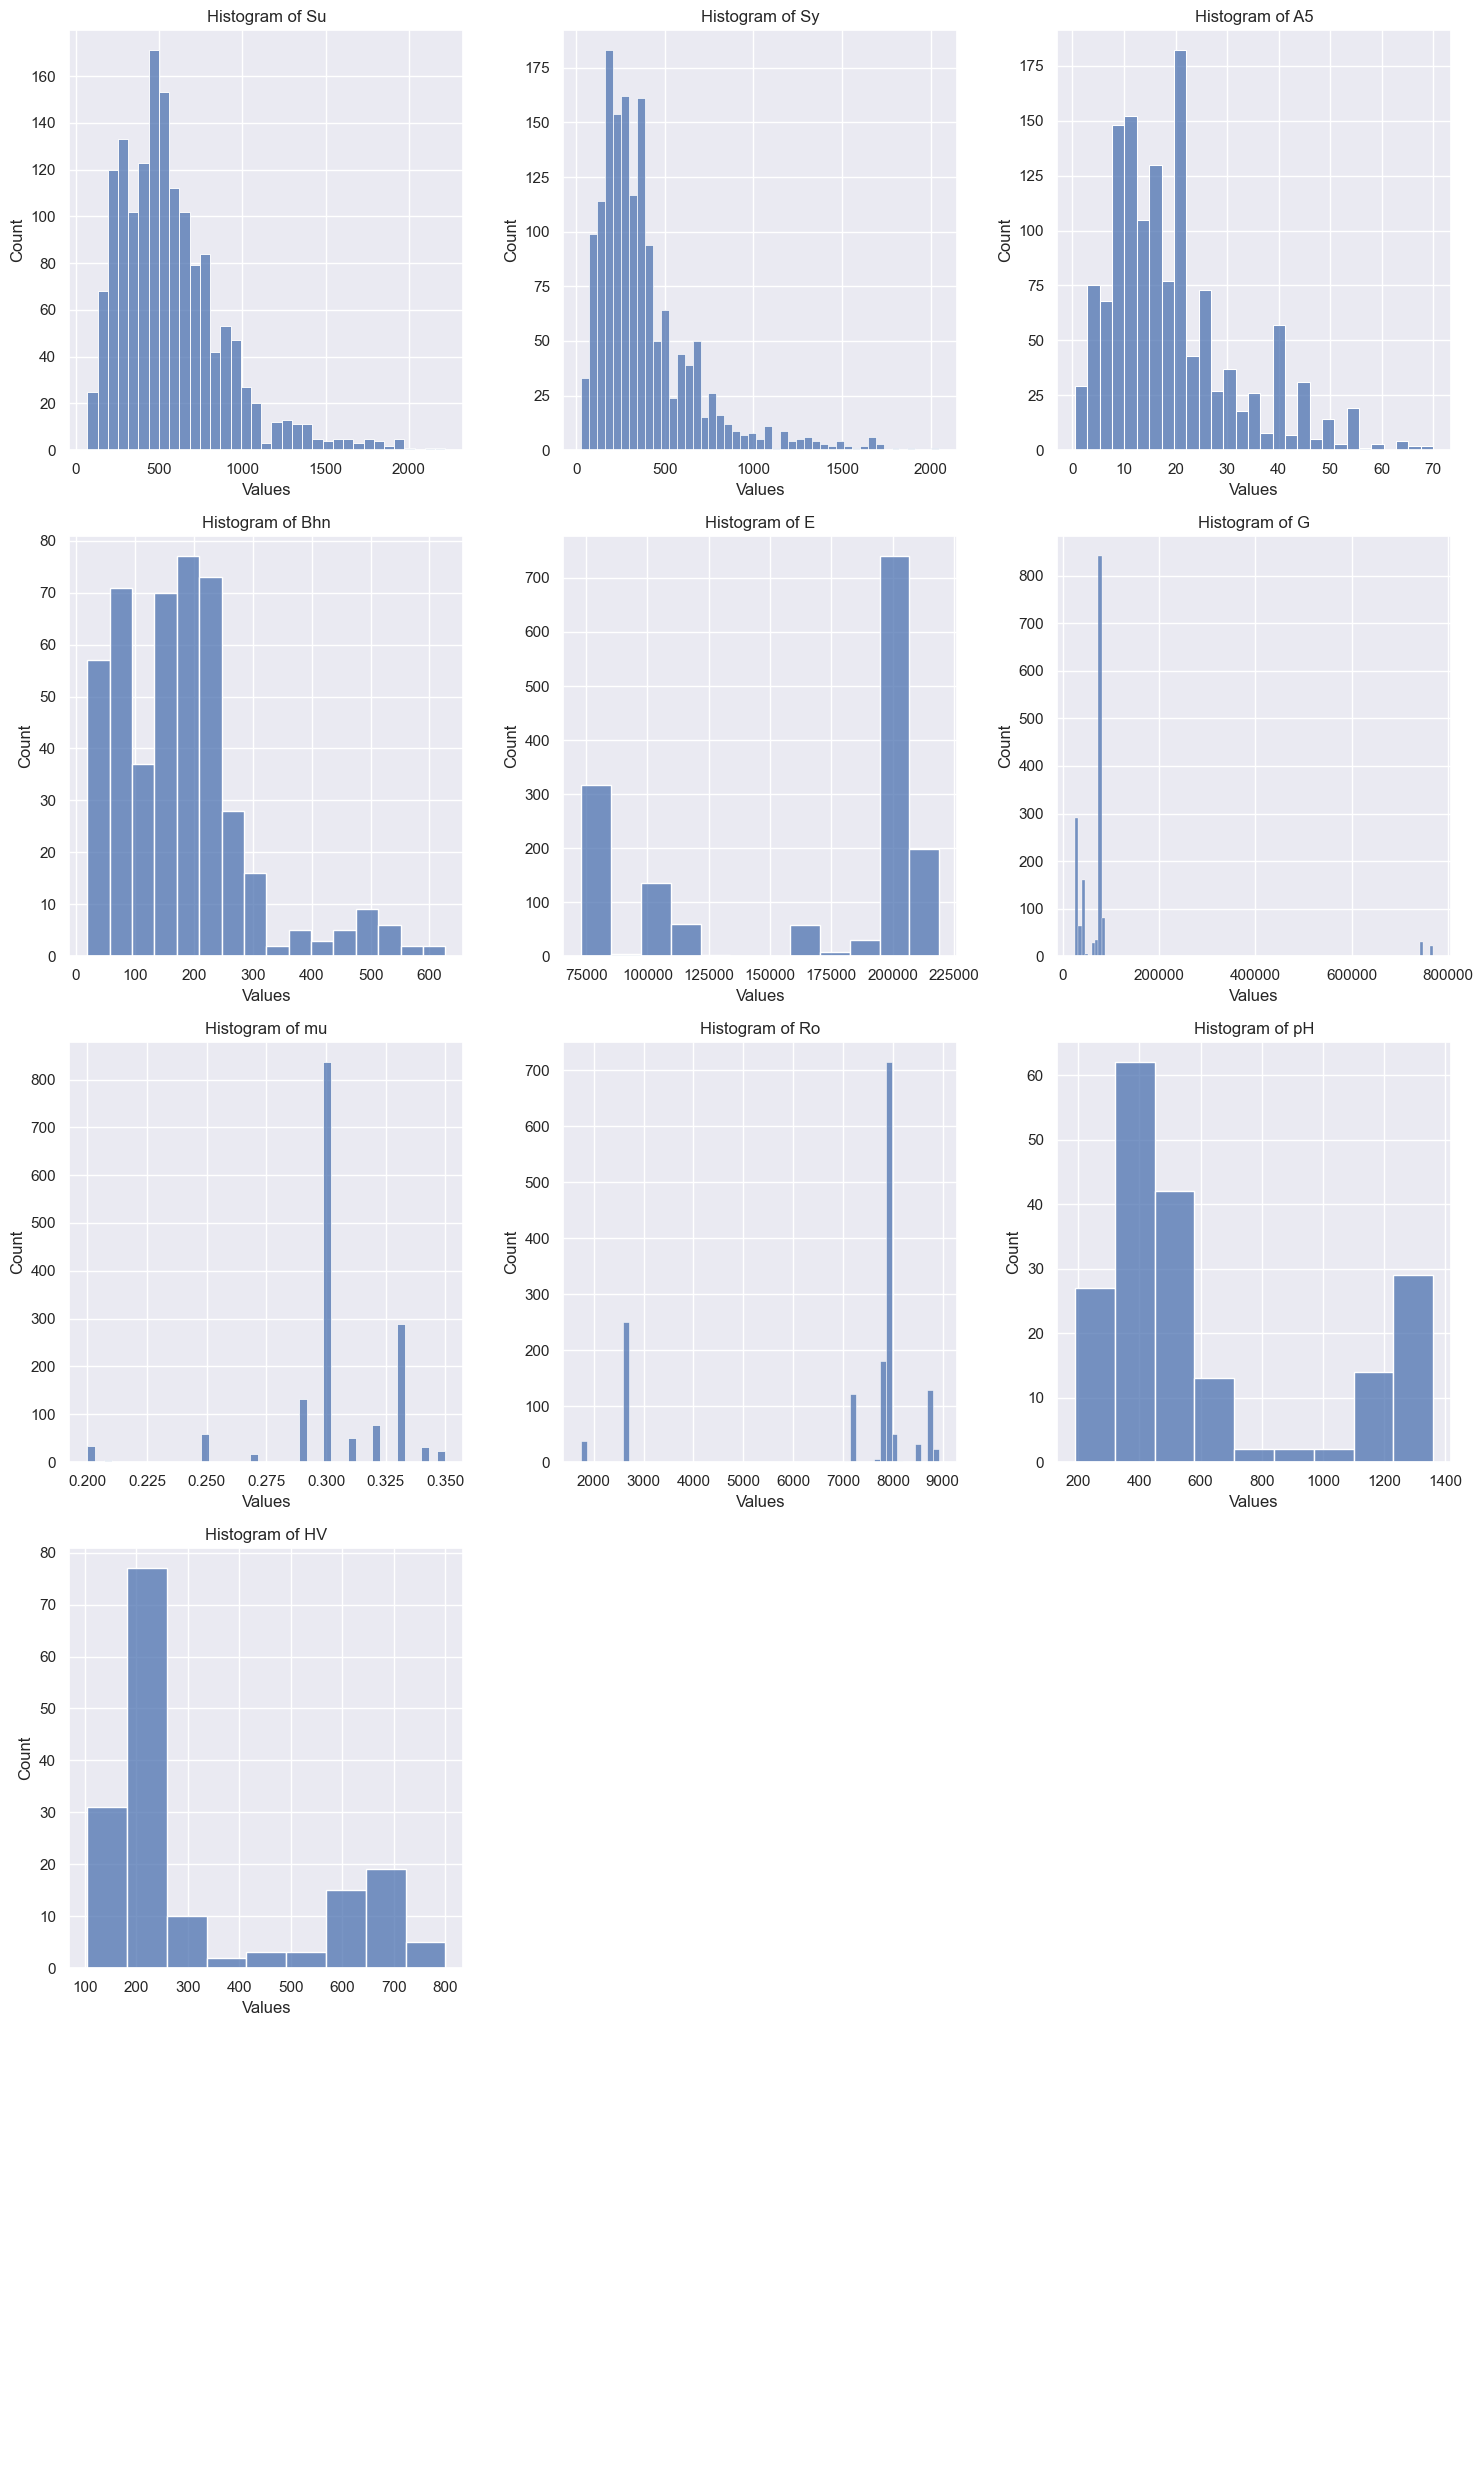

In [14]:
def plot_histplots(data):
    num_cols = df.shape[1]
    cols_per_row = 3
    rows = -(-num_cols // cols_per_row)  # Ceiling division

    # Create subplots
    fig, axes = plt.subplots(rows, cols_per_row, figsize=(5*cols_per_row,5*rows))

    # Convert axes to a flat list of Axes objects
    if rows == 1:
        axes = axes if isinstance(axes, (list, np.ndarray)) else [axes]
    else:
        axes = axes.flatten()

    # Plot each boxplot
    for i, col in enumerate(data.columns):
        sns.histplot(x=data[col], ax=axes[i])
        axes[i].set_title(f'Histogram of {col}')
        axes[i].set_xlabel('Values')

    # Hide unused subplots
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()
    
plot_histplots(numvars)

In [25]:
#method for checking Standard differences 
def material_names(df,standard):
    query_str = f"(Std == '{standard}')"
    
    status = df.query(query_str) \
        .groupby(["Material", "Heat treatment"])[["Sy"]] \
        .mean() \
        .sort_values(by=["Sy"], ascending=False) \
        .reset_index()
    
    return status

In [28]:
df_ansi = material_names(df_clean,"ANSI")
df_ansi

,Material,Heat treatment,Sy
0,Steel SAE 9255,tempered at 400 F,2048.0
1,Steel SAE 51440C,tempered at 600 F,1896.0
2,Steel SAE 5160,tempered at 400 F,1793.0
3,Steel SAE 5150,tempered at 400 F,1731.0
4,Steel SAE 4150,tempered at 400 F,1724.0
...,...,...,...
435,Aluminum Alloy B443.0,Cast (F),41.0
436,Aluminum Alloy 3003-O,Wrought,41.0
437,Aluminum Alloy 1100-O,Wrought,34.0
438,Aluminum Alloy 1060-O,Wrought,28.0


In [29]:
df_gost = material_names(df_clean, "GOST")
df_gost

,Material,Heat treatment,Sy
0,Steel 30Ch3S3GML GOST 977-88,Quenched and tempered,1472.0
1,Steel 03N12Ch5M3TJuL GOST 977-88,Quenched and tempered,1422.0
2,Steel 50ChGFA GOST 14959-79,heat treated,1325.0
3,Steel 50Ch GOST 4543-71,Quenching and cooling in the oil,1300.0
4,Steel 30ChGSA GOST 4543-71,Quenching and cooling in the oil,1300.0
...,...,...,...
185,Steel 20L GOST 977-88,normalized,216.0
186,Steel 10 GOST 1050-88,normalized,205.0
187,Steel 15L GOST 977-88,normalized,196.0
188,Steel 08 GOST 1050-88,normalized,196.0


In [30]:
df_csn = material_names(df_clean, "CSN")
df_csn

,Material,Heat treatment,Sy
0,CSN 12071,heat treated,1470.0
1,CSN 14140,nitro-case-hard.,1373.0
2,CSN 13180,heat treated,1320.0
3,CSN 14262,heat treated,1275.0
4,CSN 16640,heat treated,1275.0
...,...,...,...
59,CSN 17247,normalized,195.0
60,CSN 17241,normalized,195.0
61,CSN 17243,normalized,190.0
62,CSN 17240,normalized,186.0


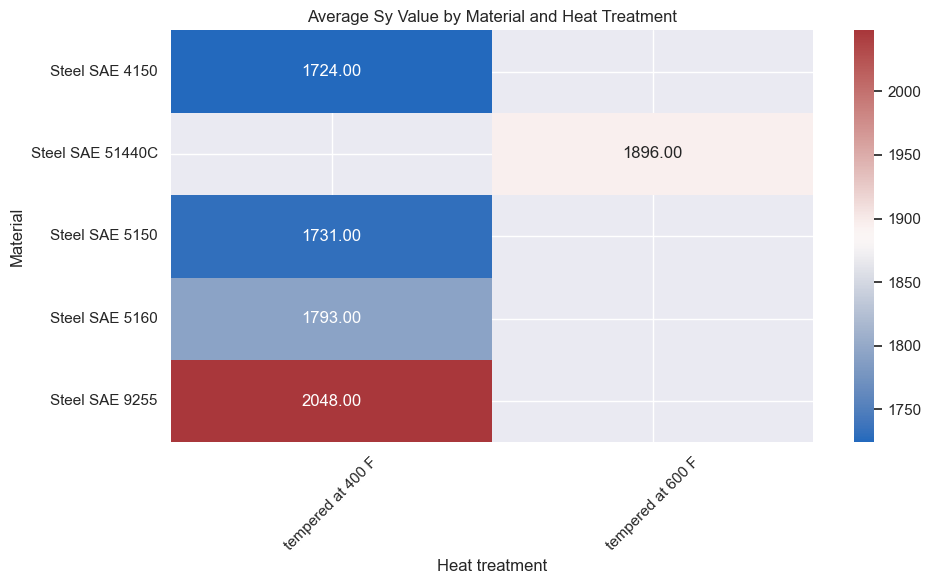

In [37]:
def standard_plots(df):
    """
    Creates a heatmap to show the average 'Sy' value
    for each combination of 'Material' and 'Heat treatment'.
    """
    # Create a pivot table to aggregate the 'Sy' column values
    pivoted_data = pd.pivot_table(
        df,
        values='Sy',
        index='Material',
        columns='Heat treatment',
        aggfunc='mean'
    )
    
    # Create the heatmap
    ax = plt.subplots(figsize=(10, 6))
    ax = sns.heatmap(pivoted_data, cmap="vlag", annot=True, fmt=".2f")
    plt.yticks(rotation=0)
    plt.xticks(rotation=45)
    
    # Set the title for clarity
    ax.set_title('Average Sy Value by Material and Heat Treatment')
    
    plt.tight_layout()
    plt.show()


# You can call the function with your DataFrame like this:
standard_plots(df_ansi.head())

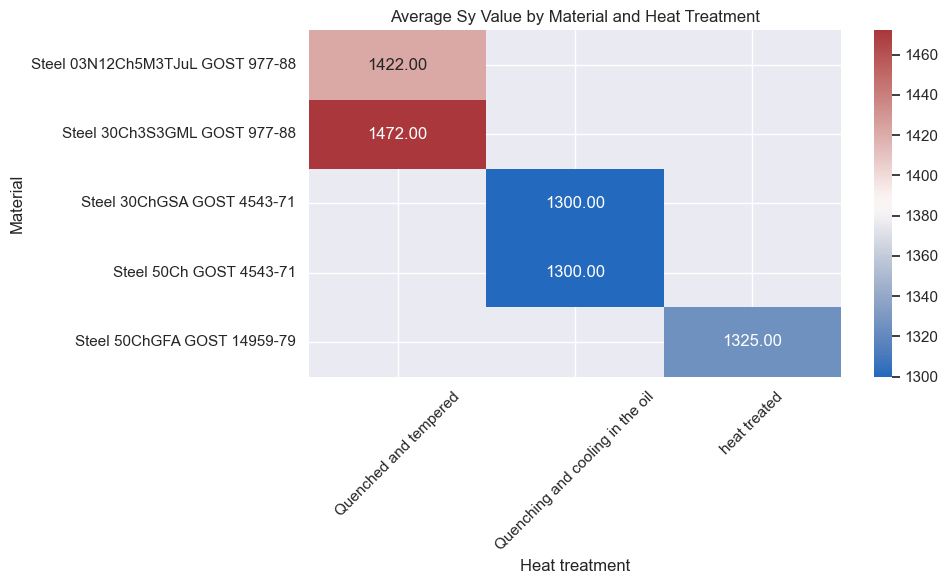

In [38]:
standard_plots(df_gost.head())

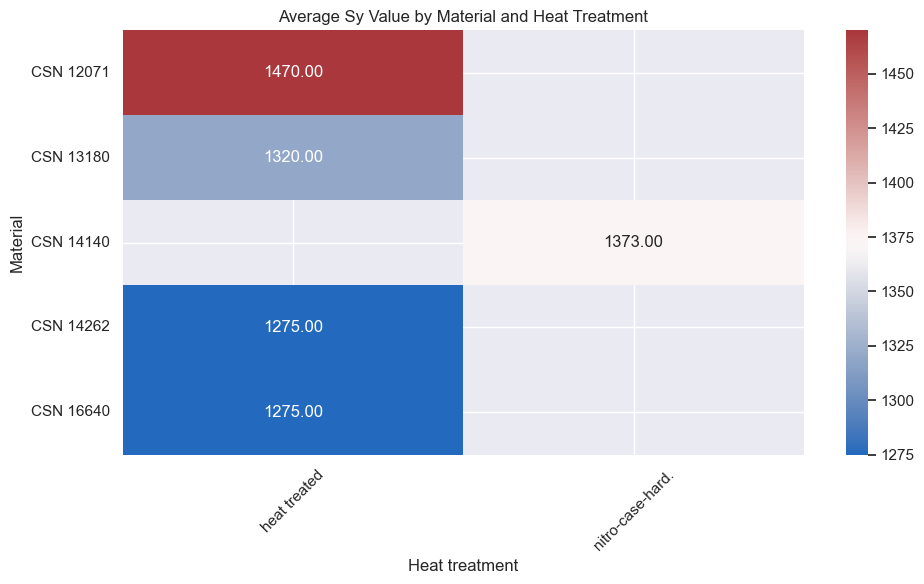

In [39]:
standard_plots(df_csn.head())